## numerical missing values impouting using Simple-impute(scikit-learn)

In [100]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
df=pd.read_csv('titanic_data_updated.csv')
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [101]:
X=df.drop(['PassengerId','Name','Ticket','Cabin','Survived'],axis=1)
X.head(3)

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,third,male,22.0,1,0,7.2500,S
1,first,female,38.0,1,0,71.2833,C
2,third,female,26.0,0,0,7.9250,S


In [102]:
y=df['Survived']
y.head(3)

0     no
1    yes
2    yes
Name: Survived, dtype: object

## Train Test

In [103]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [104]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 7)
(179, 7)
(712,)
(179,)


# fill null values using Simple imputer

In [105]:
X_train.isnull().sum ()

Pclass        0
Sex           0
Age         140
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [106]:
X_test.isnull().sum ()

Pclass       0
Sex          0
Age         37
SibSp        0
Parch        0
Fare         0
Embarked     0
dtype: int64

In [107]:
from sklearn.impute import SimpleImputer

usin simpleimputation as mean

In [108]:
age_imputer=SimpleImputer(missing_values=np.nan,strategy='mean')
age_imputer.fit(X_train[['Age']])
X_train['Age']=age_imputer.transform(X_train[['Age']])
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
331,first,male,45.500000,0,0,28.5000,S
733,second,male,23.000000,0,0,13.0000,S
382,third,male,32.000000,0,0,7.9250,S
704,third,male,26.000000,1,0,7.8542,S
813,third,female,6.000000,4,2,31.2750,S
...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,S
270,first,male,29.498846,0,0,31.0000,S
860,third,male,41.000000,2,0,14.1083,S
435,first,female,14.000000,1,2,120.0000,S


In [109]:
X_train.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    2
dtype: int64

In [110]:
X_test['Age']=age_imputer.transform(X_test[['Age']])
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
709,third,male,29.498846,1,1,15.2458,C
439,second,male,31.000000,0,0,10.5000,S
840,third,male,20.000000,0,0,7.9250,S
720,second,female,6.000000,0,1,33.0000,S
39,third,female,14.000000,1,0,11.2417,C
...,...,...,...,...,...,...,...
433,third,male,17.000000,0,0,7.1250,S
773,third,male,29.498846,0,0,7.2250,C
25,third,female,38.000000,1,5,31.3875,S
84,second,female,17.000000,0,0,10.5000,S


In [111]:
X_test.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

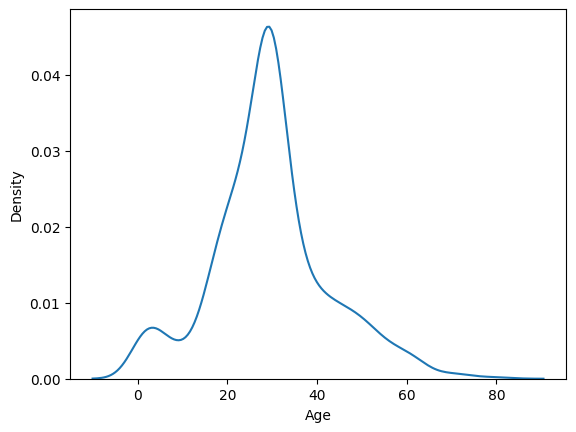

In [113]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.kdeplot(data=X_train,x='Age')
plt.show()